# EPL 2026/27 Match Prediction & League Winner Forecast

### Machine Learning + Football Analytics

This notebook turns multiple English Premier League datasets into a complete prediction workflow for the **remaining 2026/27 fixtures** and a **league-title probability forecast**.

The project has two prediction settings:

- **Pre-match:** historical team strength, form, Elo, home/away performance, rest and head-to-head information.
- **In-match:** half-time score, shots, shots on target, corners, fouls, cards and xG.

The final score is kept as the ground truth and is never used as an input to an outcome model.

## 1. Project questions

1. Which team is most likely to win each remaining 2026/27 EPL match?
2. What are the predicted Home / Draw / Away probabilities?
3. Which team has the highest probability of winning the league?
4. How do referees differ in their historical foul and card patterns?
5. How much does in-match information improve outcome prediction over a pre-match model?

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

BASE = Path("..")
DATA = BASE / "data"
RESULTS = BASE / "results"
MODELS = BASE / "models"

print("Project root:", BASE.resolve())

Project root: /mnt/data/epl_2026_27_full_project


## 2. Data sources and integration

The repository combines three user-supplied datasets:

- `epl_final.csv` — historical EPL match results and match statistics.
- `epl-allseasons-matchstats.csv` — additional match statistics and referee names.
- `Book1.xlsx` — referee + xG data for recent seasons, including the available 2025/26 records.

The integrated historical table standardizes team names and uses a match key based on date + home team + away team to prevent duplicate fixtures.

For the 2026/27 schedule, the repository uses the released 380-match fixture list and the completed Matchweeks 1–5. Fixtures can be changed by the league, so predictions should be regenerated after schedule updates.

**Current project snapshot:** 8 October 2026.

In [2]:
raw = pd.read_csv(DATA / "raw/epl_final.csv")
combined = pd.read_csv(DATA / "processed/epl_combined_historical.csv", parse_dates=["MatchDate"])
current = pd.read_csv(DATA / "processed/2026_27_completed_mw1_mw5.csv")
upcoming = pd.read_csv(RESULTS / "2026_27_all_upcoming_match_predictions.csv")

print("Original dataset:", raw.shape)
print("Integrated historical dataset:", combined.shape)
print("Completed 2026/27 matches:", len(current))
print("Remaining 2026/27 fixtures:", len(upcoming))
print("Completed historical matches:", combined["FullTimeResult"].notna().sum())

Original dataset: (9380, 22)
Integrated historical dataset: (9579, 27)
Completed 2026/27 matches: 50
Remaining 2026/27 fixtures: 330
Completed historical matches: 9579


In [3]:
print("Integrated seasons:")
print(combined["Season"].value_counts().sort_index().to_string())

print("\nMissing values in key target columns:")
print(combined[["HomeTeam","AwayTeam","FullTimeHomeGoals","FullTimeAwayGoals","FullTimeResult"]].isna().sum())

print("\nDuplicate match keys:", combined["MatchKey"].duplicated().sum())

Integrated seasons:
Season
2000/01    380
2001/02    380
2002/03    380
2003/04    335
2004/05    335
2005/06    380
2006/07    380
2007/08    380
2008/09    380
2009/10    380
2010/11    380
2011/12    380
2012/13    380
2013/14    380
2014/15    380
2015/16    380
2016/17    380
2017/18    380
2018/19    380
2019/20    380
2020/21    380
2021/22    380
2022/23    380
2023/24    380
2024/25    380
2025/26    169

Missing values in key target columns:
HomeTeam             0
AwayTeam             0
FullTimeHomeGoals    0
FullTimeAwayGoals    0
FullTimeResult       0
dtype: int64

Duplicate match keys: 0


## 3. Prediction target

The classification target is `FullTimeResult`:

- `H` = home win
- `D` = draw
- `A` = away win

The Linear Regression baseline predicts `GoalDifference` and converts that continuous estimate into H/D/A.

For the in-match model, the current match statistics are valid inputs because the prediction is assumed to be made during the match. However, `FullTimeHomeGoals` and `FullTimeAwayGoals` are excluded from the feature matrix because they reveal the answer.

In [4]:
metrics_pre = pd.read_csv(RESULTS / "model_metrics_2024_25.csv")
metrics_live = pd.read_csv(RESULTS / "model_metrics_inmatch_2024_25.csv")

print("Pre-match backtest")
display(metrics_pre)
print("\nIn-match backtest")
display(metrics_live)

Pre-match backtest


,Model,Accuracy,Macro_F1,MAE,RMSE,R2
0,Linear Regression — goal difference,0.410526,0.366800,1.427925,1.86374,-0.000124
1,XGBoost — H/D/A,0.465789,0.346287,NaN,NaN,NaN



In-match backtest


,Model,Accuracy,Macro_F1,MAE,RMSE,R2
0,Linear Regression — in-match,0.654286,0.597563,0.947715,1.2749,0.542655
1,XGBoost — in-match,0.628571,0.571316,NaN,NaN,NaN


## 4. Model performance

The 2024/25 backtest uses a chronological train/test split, so future seasons are not randomly mixed into the training set.

This is important for a real forecasting problem: the model must learn from the past and then predict later matches.

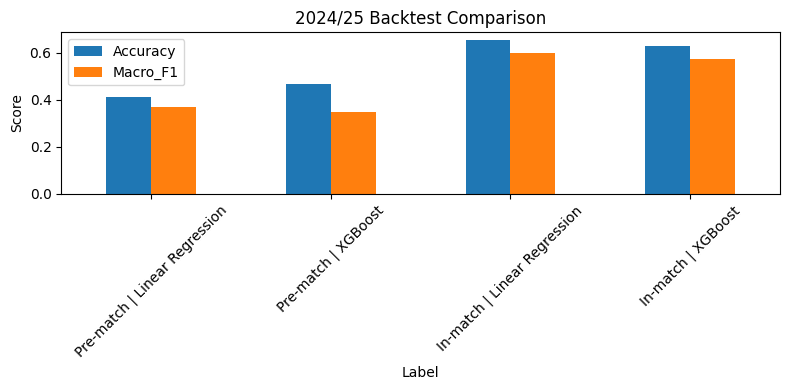

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_df = pd.concat([
    metrics_pre[["Model", "Accuracy", "Macro_F1"]].assign(Scope="Pre-match"),
    metrics_live[["Model", "Accuracy", "Macro_F1"]].assign(Scope="In-match")
])
plot_df["Label"] = plot_df["Scope"] + " | " + plot_df["Model"].str.split(" — ").str[0]
plot_df.set_index("Label")[["Accuracy", "Macro_F1"]].plot(kind="bar", ax=ax)
ax.set_title("2024/25 Backtest Comparison")
ax.set_ylabel("Score")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 5. Referee analysis

Referee behavior is summarized using historical averages rather than treating the referee as a causal explanation for match results.

The most useful variables are:

- Average fouls per match
- Average yellow cards
- Average red cards
- Home-vs-away yellow-card bias
- Historical H/D/A rates

For future fixtures, referee assignments may not be available far enough in advance. Therefore, the full-season pre-match forecast remains referee-neutral and the referee module can be applied once an appointment is known.

In [6]:
ref = pd.read_csv(DATA / "processed/referee_impact_profile.csv")

print("Number of referees:", ref["Referee"].nunique())
display(ref.sort_values("Matches", ascending=False).head(15))

Number of referees: 67


,Referee,Matches,Avg_Total_Fouls,Avg_Total_Yellow,Avg_Total_Red,Home_Yellow_Bias,Home_Win_Rate,Draw_Rate,Away_Win_Rate
0,M Dean,288,21.343750,3.746528,0.180556,-0.128472,0.454861,0.274306,0.270833
1,M Atkinson,281,21.505338,3.366548,0.160142,-0.427046,0.459075,0.241993,0.298932
2,M Oliver,266,21.988722,3.169173,0.131579,-0.214286,0.443609,0.281955,0.274436
3,A Taylor,256,21.269531,3.468750,0.140625,-0.070312,0.464844,0.214844,0.320312
4,A Marriner,249,20.152610,3.168675,0.148594,-0.228916,0.441767,0.240964,0.317269
5,J Moss,225,21.791111,3.413333,0.142222,-0.257778,0.444444,0.195556,0.360000
6,K Friend,216,21.763889,3.444444,0.101852,-0.185185,0.462963,0.250000,0.287037
7,L Mason,215,22.060465,3.134884,0.125581,-0.279070,0.469767,0.232558,0.297674
8,M Clattenburg,175,21.628571,3.177143,0.177143,-0.365714,0.468571,0.257143,0.274286
9,M Jones,170,23.082353,3.158824,0.135294,-0.358824,0.470588,0.258824,0.270588


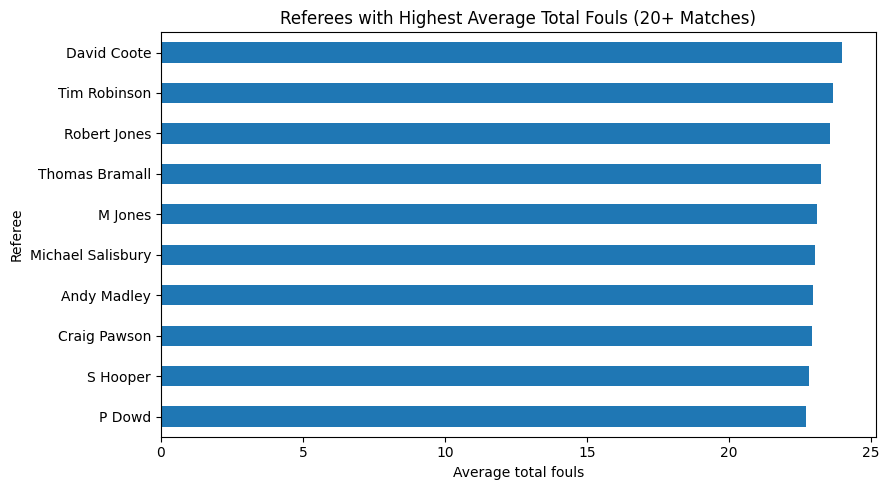

In [7]:
top_ref_fouls = ref[ref["Matches"] >= 20].sort_values("Avg_Total_Fouls", ascending=False).head(10)
ax = top_ref_fouls.plot(kind="barh", x="Referee", y="Avg_Total_Fouls", figsize=(9, 5), legend=False)
ax.set_title("Referees with Highest Average Total Fouls (20+ Matches)")
ax.set_xlabel("Average total fouls")
ax.set_ylabel("Referee")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 6. Current 2026/27 table after Matchweek 5

The first five matchweeks are treated as completed results and used to update the current team state before predicting Matchweek 6 onward.

In [8]:
current_table = pd.read_csv(RESULTS / "2026_27_current_table_after_mw5.csv")
display(current_table)

,Team,Played,W,D,L,GF,GA,GD,Points,Position
0,Man City,5,5,0,0,13,5,8,15,1
1,Arsenal,5,4,0,1,8,4,4,12,2
2,Brighton,5,3,1,1,16,5,11,10,3
3,Brentford,5,2,3,0,10,4,6,9,4
4,Leeds,5,2,3,0,7,3,4,9,5
5,Liverpool,5,2,3,0,7,4,3,9,6
6,Everton,5,2,3,0,6,3,3,9,7
7,Hull,5,2,2,1,6,4,2,8,8
8,Newcastle,5,2,2,1,9,9,0,8,9
9,Chelsea,5,2,1,2,10,12,-2,7,10


## 7. Predict all remaining 2026/27 fixtures

There are **330 remaining fixtures** from Matchweeks 6–38 in this project snapshot.

The pre-match model generates three probabilities for every match:

`HomeWin_Probability`, `Draw_Probability`, `AwayWin_Probability`

and the highest probability becomes the model prediction.

In [9]:
show_cols = [
    "Matchweek", "HomeTeam", "AwayTeam", "MatchweekStartDate",
    "HomeWin_Probability", "Draw_Probability", "AwayWin_Probability",
    "Prediction", "Confidence"
]

upcoming["MatchweekStartDate"] = pd.to_datetime(upcoming["MatchweekStartDate"])
display(upcoming[show_cols].head(20))
print("Rows predicted:", len(upcoming))

,Matchweek,HomeTeam,AwayTeam,MatchweekStartDate,HomeWin_Probability,Draw_Probability,AwayWin_Probability,Prediction,Confidence
0,6,Arsenal,Leeds,2026-10-10,0.591303,0.158966,0.249731,H,0.591303
1,6,Sunderland,Brighton,2026-10-10,0.278108,0.317325,0.404567,A,0.404567
2,6,Chelsea,Bournemouth,2026-10-10,0.514665,0.227945,0.257390,H,0.514665
3,6,Ipswich,Fulham,2026-10-10,0.285375,0.224853,0.489772,A,0.489772
4,6,Aston Villa,Brentford,2026-10-10,0.493684,0.270649,0.235667,H,0.493684
5,6,Man United,Tottenham,2026-10-10,0.433155,0.292391,0.274454,H,0.433155
6,6,Hull,Everton,2026-10-10,0.326960,0.384480,0.288561,D,0.384480
7,6,Crystal Palace,Nott'm Forest,2026-10-10,0.405155,0.218089,0.376756,H,0.405155
8,6,Liverpool,Man City,2026-10-10,0.319350,0.252556,0.428094,A,0.428094
9,6,Coventry,Newcastle,2026-10-10,0.190695,0.179640,0.629665,A,0.629665


Rows predicted: 330


In [10]:
# Export a compact complete forecast table for GitHub readers.
forecast_summary = upcoming[show_cols].copy()
forecast_summary.to_csv(RESULTS / "2026_27_all_upcoming_predictions_compact.csv", index=False)

print("Prediction counts:")
print(upcoming["Prediction"].value_counts())

Prediction counts:
Prediction
H    197
A    117
D     16
Name: count, dtype: int64


## 8. Arsenal fixture forecast

This is a focused view for the team most often discussed in the project. The same table structure can be filtered for any EPL club.

In [11]:
arsenal = upcoming[(upcoming["HomeTeam"] == "Arsenal") | (upcoming["AwayTeam"] == "Arsenal")].copy()
display(arsenal[show_cols].to_string(index=False))

" Matchweek       HomeTeam       AwayTeam MatchweekStartDate  HomeWin_Probability  Draw_Probability  AwayWin_Probability Prediction  Confidence\n         6        Arsenal          Leeds         2026-10-10             0.591303          0.158966             0.249731          H    0.591303\n         7  Nott'm Forest        Arsenal         2026-10-17             0.213335          0.182140             0.604525          A    0.604525\n         8        Arsenal        Everton         2026-10-23             0.654052          0.157193             0.188754          H    0.654052\n         9      Liverpool        Arsenal         2026-10-31             0.393852          0.257056             0.349091          H    0.393852\n        10        Arsenal           Hull         2026-11-07             0.491675          0.182343             0.325983          H    0.491675\n        11      Newcastle        Arsenal         2026-11-21             0.342201          0.263950             0.393849          A    0

## 9. Predicted final league table

Expected final points are calculated from the predicted 1X2 probabilities across all remaining fixtures and added to the points already earned after Matchweek 5.

In [12]:
expected = pd.read_csv(RESULTS / "2026_27_expected_final_table.csv")
expected.insert(0, "ProjectedPosition", np.arange(1, len(expected) + 1))
display(expected)

,ProjectedPosition,Team,CurrentPoints,ExpectedFinalPoints,ExpectedRank
0,1,Man City,15,82.188222,1
1,2,Arsenal,12,71.298140,2
2,3,Liverpool,9,63.751325,3
3,4,Newcastle,8,58.003174,4
4,5,Aston Villa,4,57.267728,5
5,6,Chelsea,7,56.885902,6
6,7,Brighton,10,55.973534,7
7,8,Brentford,9,53.253392,8
8,9,Everton,9,52.999452,9
9,10,Man United,5,50.207356,10


## 10. League winner forecast with Monte Carlo simulation

To estimate title probability, the project simulates **20,000 possible completions of the remaining season**.

Each remaining fixture is sampled from the XGBoost Home/Draw/Away probabilities. The simulation starts from the actual points after Matchweek 5.

This is an approximate season forecast because the fixture probabilities are held fixed at the current model state rather than dynamically retraining after every simulated result.

In [13]:
title = pd.read_csv(RESULTS / "2026_27_title_race_monte_carlo.csv")
display(title.head(10))

,Team,Title_Probability,Top4_Probability,Mean_Finish,Expected_Final_Points,ProjectedRank
0,Man City,0.80540,0.99560,1.25410,82.15210,1
1,Arsenal,0.14860,0.90635,2.61385,71.27720,2
2,Liverpool,0.02810,0.61145,4.54600,63.85495,3
3,Newcastle,0.00515,0.27875,7.03365,58.02060,4
4,Aston Villa,0.00410,0.27900,7.19665,57.32915,5
5,Chelsea,0.00365,0.24890,7.40245,56.82590,6
6,Brighton,0.00225,0.20445,7.84855,55.95970,7
7,Brentford,0.00110,0.12540,9.22270,53.25840,8
8,Everton,0.00055,0.11445,9.36985,53.02450,9
9,Crystal Palace,0.00030,0.05735,11.11750,49.86155,10


In [14]:
winner = title.iloc[0]
print(f"Modelled league winner: {winner['Team']}")
print(f"Title probability: {winner['Title_Probability']:.2%}")
print(f"Expected final points: {winner['Expected_Final_Points']:.1f}")
print(f"Top-4 probability: {winner['Top4_Probability']:.2%}")

Modelled league winner: Man City
Title probability: 80.54%
Expected final points: 82.2
Top-4 probability: 99.56%


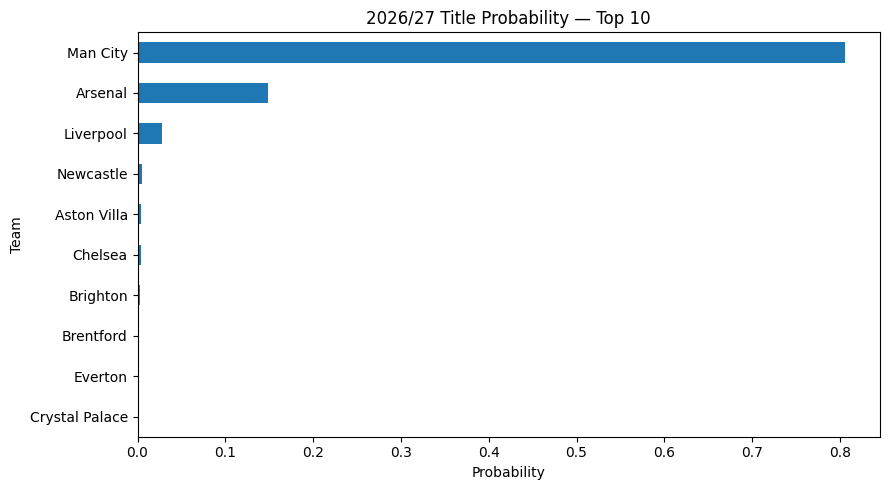

In [15]:
plot = title.head(10).sort_values("Title_Probability")
ax = plot.plot(kind="barh", x="Team", y="Title_Probability", figsize=(9, 5), legend=False)
ax.set_title("2026/27 Title Probability — Top 10")
ax.set_xlabel("Probability")
ax.set_ylabel("Team")
plt.tight_layout()
plt.show()

## 11. Interpretation

### Current title picture

The model currently places **Manchester City** as the leading title candidate, with Arsenal as the main challenger in the simulation.

### How to read the result

A `70%` title probability does **not** mean the team is guaranteed to win. It means that under the model's probability assumptions, that team won the simulated league most often.

### Referee information

Referee behavior is best used as an additional contextual feature when a referee appointment is known. It should not be interpreted as proof that an individual referee causes a particular result.

## 12. Updating the project during 2026/27

After every completed matchweek:

1. Add the new match results to the current-season results file.
2. Rebuild Elo and rolling form using all completed matches.
3. Retrain or refit the models.
4. Remove completed fixtures from the prediction set.
5. Regenerate the 1X2 probabilities.
6. Rerun the Monte Carlo title simulation.

This keeps the project useful throughout the season instead of producing one static prediction at the start of the campaign.

## 13. Conclusion

The project combines real-world sports data engineering with machine learning. The main output is a complete 2026/27 fixture forecast, while the Monte Carlo layer converts individual match probabilities into a season-level title forecast.

The strongest extension for future work is a **dynamic simulation model** that updates team Elo/form after every simulated match, followed by a live dashboard that refreshes predictions as new results, referee assignments and in-match statistics become available.